In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import plotly.express as px
from sklearn.preprocessing import LabelEncoder

In [4]:
df = pd.read_csv("vitamin_deficiency_disease_dataset_20260123.csv")

In [5]:
df.columns

Index(['age', 'gender', 'bmi', 'smoking_status', 'alcohol_consumption',
       'exercise_level', 'diet_type', 'sun_exposure', 'income_level',
       'latitude_region', 'vitamin_a_percent_rda', 'vitamin_c_percent_rda',
       'vitamin_d_percent_rda', 'vitamin_e_percent_rda',
       'vitamin_b12_percent_rda', 'folate_percent_rda', 'calcium_percent_rda',
       'iron_percent_rda', 'hemoglobin_g_dl', 'serum_vitamin_d_ng_ml',
       'serum_vitamin_b12_pg_ml', 'serum_folate_ng_ml', 'symptoms_count',
       'symptoms_list', 'has_night_blindness', 'has_fatigue',
       'has_bleeding_gums', 'has_bone_pain', 'has_muscle_weakness',
       'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin',
       'disease_diagnosis', 'has_multiple_deficiencies'],
      dtype='object')

In [6]:
df.head()

,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,...,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,disease_diagnosis,has_multiple_deficiencies
0,79,Male,24.8,Former,NaN,Active,Vegetarian,High,High,Mid,...,0,0,0,0,0,0,0,0,Healthy,0
1,77,Female,39.9,Former,Moderate,Light,Omnivore,Low,Low,Low,...,0,0,0,1,0,0,0,0,Rickets_Osteomalacia,0
2,24,Male,26.4,Former,Heavy,Moderate,Omnivore,Low,High,High,...,1,0,0,0,0,0,0,0,Healthy,0
3,69,Male,23.1,Never,Heavy,Moderate,Vegetarian,High,Low,Low,...,0,0,0,0,0,1,1,0,Anemia,0
4,63,Male,29.6,Never,NaN,Moderate,Vegetarian,Moderate,High,Low,...,0,0,0,0,0,0,0,0,Healthy,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        4000 non-null   int64  
 1   gender                     4000 non-null   object 
 2   bmi                        4000 non-null   float64
 3   smoking_status             4000 non-null   object 
 4   alcohol_consumption        2722 non-null   object 
 5   exercise_level             4000 non-null   object 
 6   diet_type                  4000 non-null   object 
 7   sun_exposure               4000 non-null   object 
 8   income_level               4000 non-null   object 
 9   latitude_region            4000 non-null   object 
 10  vitamin_a_percent_rda      4000 non-null   float64
 11  vitamin_c_percent_rda      4000 non-null   float64
 12  vitamin_d_percent_rda      4000 non-null   float64
 13  vitamin_e_percent_rda      4000 non-null   float

In [8]:
df1 = df.dropna()

In [9]:
df1.columns

Index(['age', 'gender', 'bmi', 'smoking_status', 'alcohol_consumption',
       'exercise_level', 'diet_type', 'sun_exposure', 'income_level',
       'latitude_region', 'vitamin_a_percent_rda', 'vitamin_c_percent_rda',
       'vitamin_d_percent_rda', 'vitamin_e_percent_rda',
       'vitamin_b12_percent_rda', 'folate_percent_rda', 'calcium_percent_rda',
       'iron_percent_rda', 'hemoglobin_g_dl', 'serum_vitamin_d_ng_ml',
       'serum_vitamin_b12_pg_ml', 'serum_folate_ng_ml', 'symptoms_count',
       'symptoms_list', 'has_night_blindness', 'has_fatigue',
       'has_bleeding_gums', 'has_bone_pain', 'has_muscle_weakness',
       'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin',
       'disease_diagnosis', 'has_multiple_deficiencies'],
      dtype='object')

In [11]:
df2 = df1.drop(columns=['latitude_region','income_level'])

In [13]:
le = LabelEncoder()

In [23]:
for col in df2.columns:
    if df2[col].dtype == 'object':
        df2[col] = le.fit_transform(df2[col].astype('str'))

In [24]:
x = df2.drop('disease_diagnosis',axis=1)
y = df2['disease_diagnosis']

In [25]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1838 entries, 1 to 3998
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        1838 non-null   int64  
 1   gender                     1838 non-null   int64  
 2   bmi                        1838 non-null   float64
 3   smoking_status             1838 non-null   int64  
 4   alcohol_consumption        1838 non-null   int64  
 5   exercise_level             1838 non-null   int64  
 6   diet_type                  1838 non-null   int64  
 7   sun_exposure               1838 non-null   int64  
 8   vitamin_a_percent_rda      1838 non-null   float64
 9   vitamin_c_percent_rda      1838 non-null   float64
 10  vitamin_d_percent_rda      1838 non-null   float64
 11  vitamin_e_percent_rda      1838 non-null   float64
 12  vitamin_b12_percent_rda    1838 non-null   float64
 13  folate_percent_rda         1838 non-null   float64
 1

In [26]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
RFC = RandomForestClassifier()
RFC.fit(x_train,y_train)

RandomForestClassifier()

In [28]:
y_pred = RFC.predict(x_test)

In [29]:
accuracy_score(y_test,y_pred)

0.967391304347826

In [30]:
imp = RFC.feature_importances_

In [31]:
imp

array([0.01310527, 0.00211863, 0.01485867, 0.00364068, 0.00204824,
       0.00502239, 0.00747272, 0.05538212, 0.06465956, 0.05394003,
       0.20112209, 0.01431174, 0.06017491, 0.02636436, 0.01611916,
       0.03092662, 0.01419522, 0.10764269, 0.03585925, 0.01858822,
       0.02384802, 0.05738183, 0.01343251, 0.01689051, 0.009286  ,
       0.02500024, 0.02737915, 0.01049645, 0.0106313 , 0.00669045,
       0.05141099])

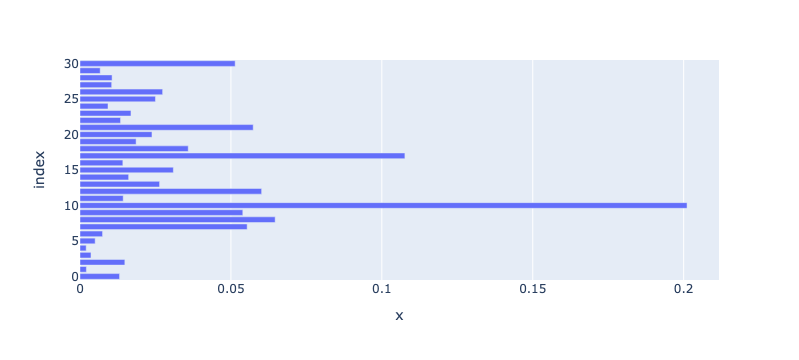

In [33]:
px.bar(x.columns,imp)

<BarContainer object of 31 artists>

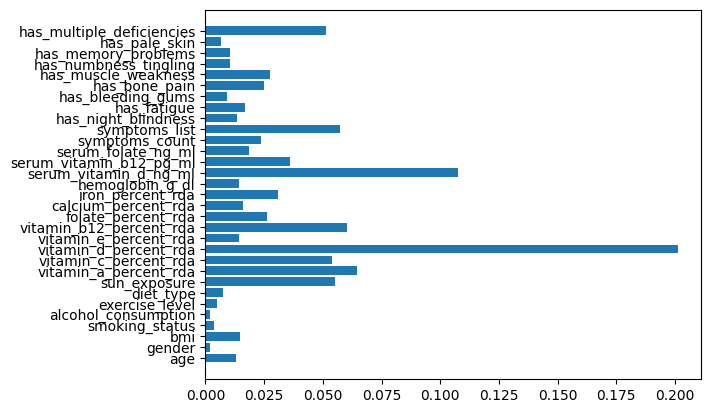

In [34]:
plt.barh(x.columns,imp)